In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load the CSV file

In [2]:
df = pd.read_csv("../data/cve_data.csv", sep=";")

Drop "N/A" values in every relevant column

In [3]:
cols_to_check = ["CWE", "Vendor", "Product", "CVSS", "EPSS", "Date"]
for col in cols_to_check:
    df = df[df[col] != "N/A"]

Convert the columns we need

In [4]:
df["CVSS"] = pd.to_numeric(df["CVSS"], errors="coerce")
df["EPSS"] = pd.to_numeric(df["EPSS"], errors="coerce")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True)

Weakness types (CWE), bar chart

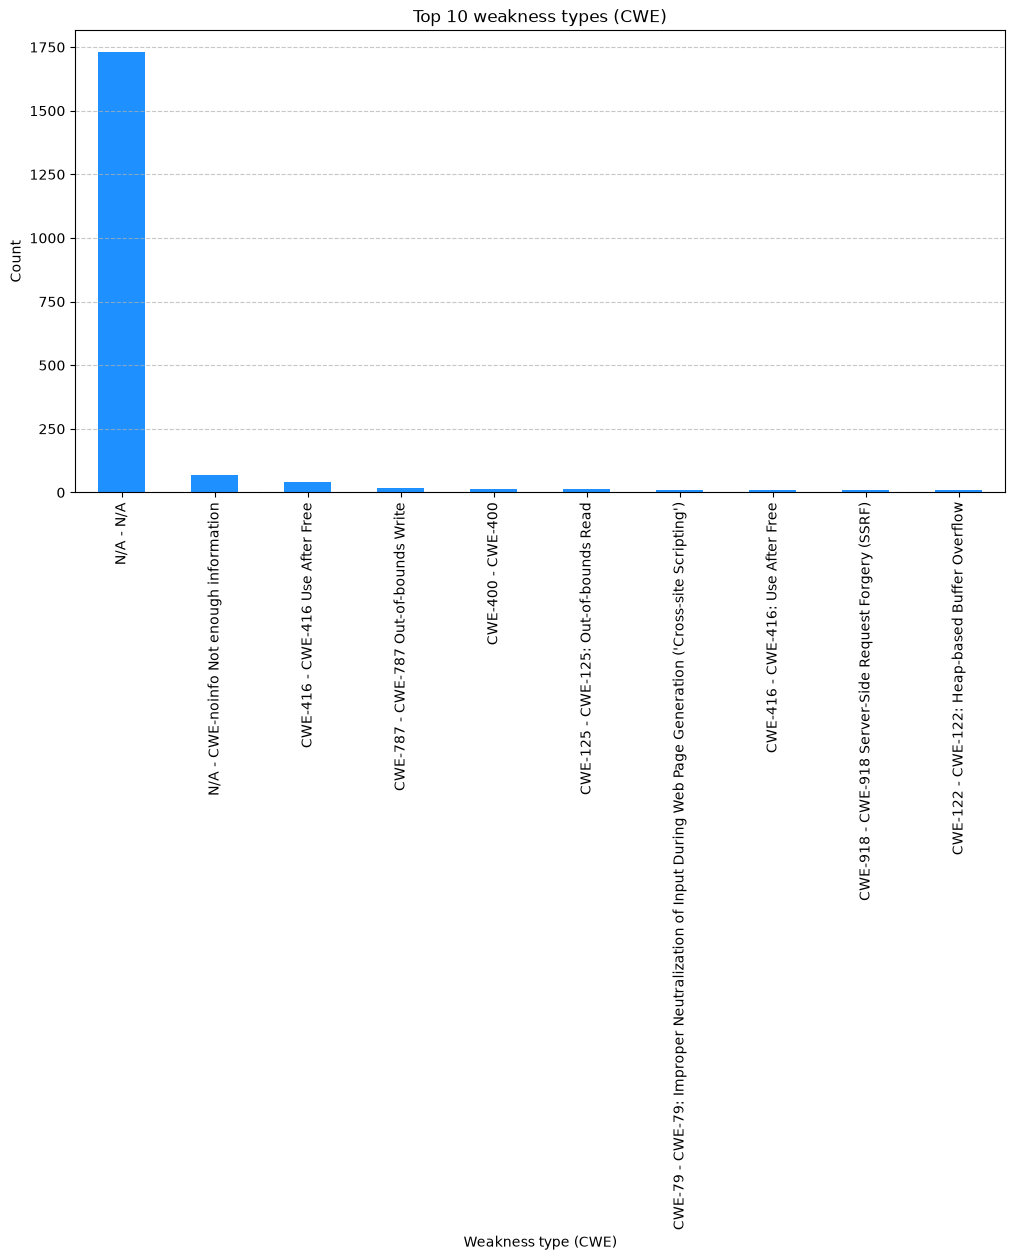

In [5]:
plt.figure(figsize=(12,6))
df['CWE'].value_counts().head(10).plot(kind='bar', color='dodgerblue')
plt.title("Top 10 weakness types (CWE)")
plt.xlabel('Weakness type (CWE)')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

EPSS score distribution

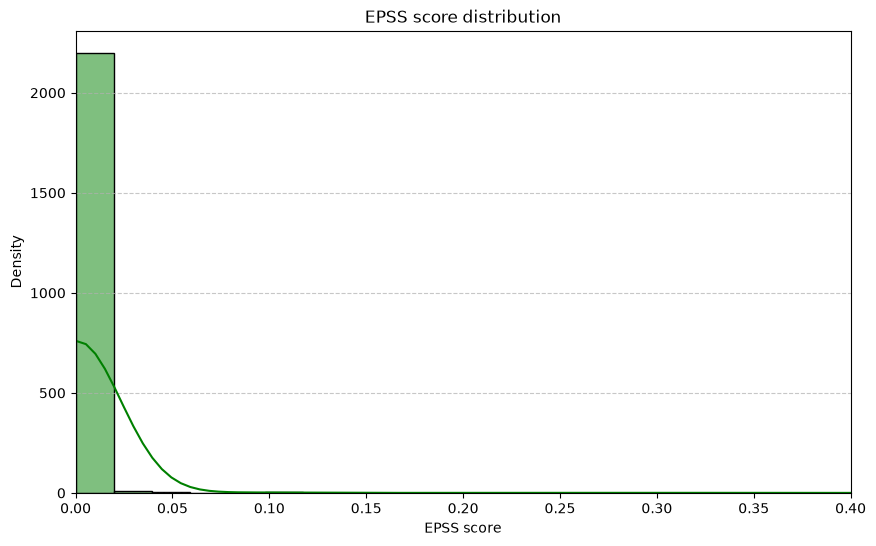

In [6]:
plt.figure(figsize=(10,6))
sns.histplot(df['EPSS'].dropna(), bins=50, kde=True, color='green')
plt.xlim(0,0.4)
plt.title('EPSS score distribution')
plt.xlabel('EPSS score')
plt.ylabel('Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

CVSS and EPSS: scatter plot and correlation heatmap

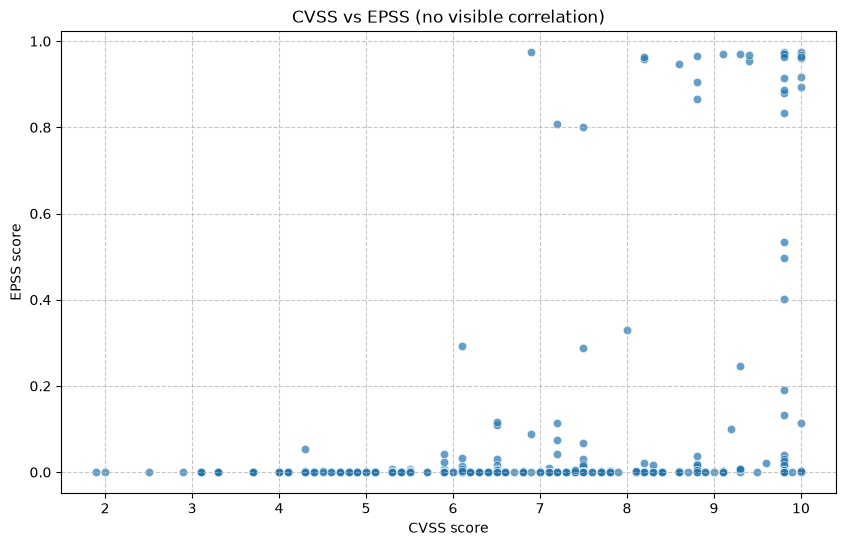

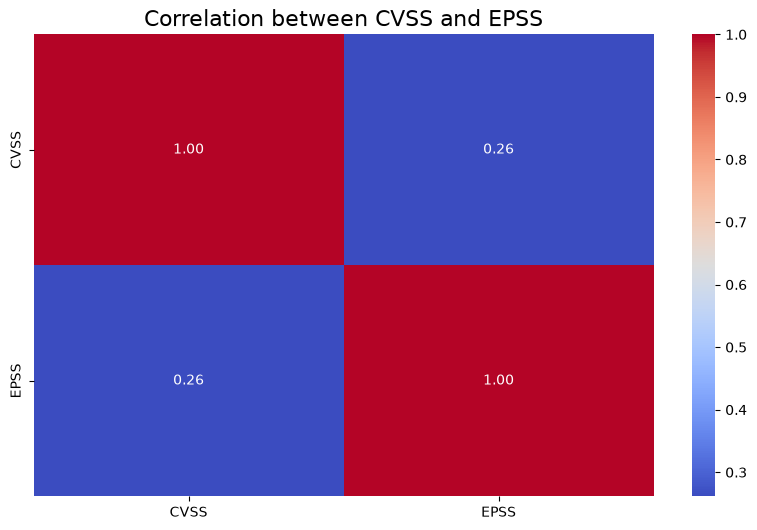

In [7]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='CVSS', y='EPSS', data=df, alpha=0.7)
plt.title('CVSS vs EPSS (no visible correlation)')
plt.xlabel('CVSS score')
plt.ylabel('EPSS score')
plt.grid(linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(10, 6))
correlation_matrix = df[['CVSS', 'EPSS']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation between CVSS and EPSS", fontsize=16)
plt.show()

Vulnerabilities per month

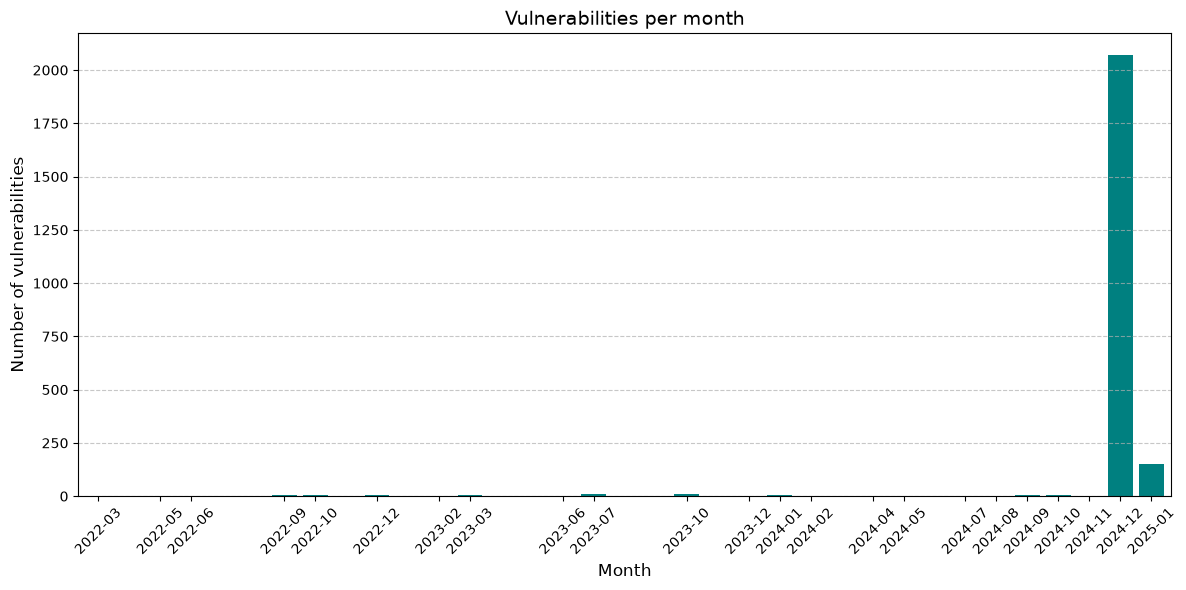

In [8]:
# month of each bulletin
df['Month'] = df['Date'].dt.tz_localize(None).dt.to_period('M')

vuln_per_month = df.groupby('Month').size()

plt.figure(figsize=(12, 6))
vuln_per_month.plot(kind='bar', color='teal', width=0.8)
plt.title("Vulnerabilities per month", fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of vulnerabilities', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Vulnerabilities per product

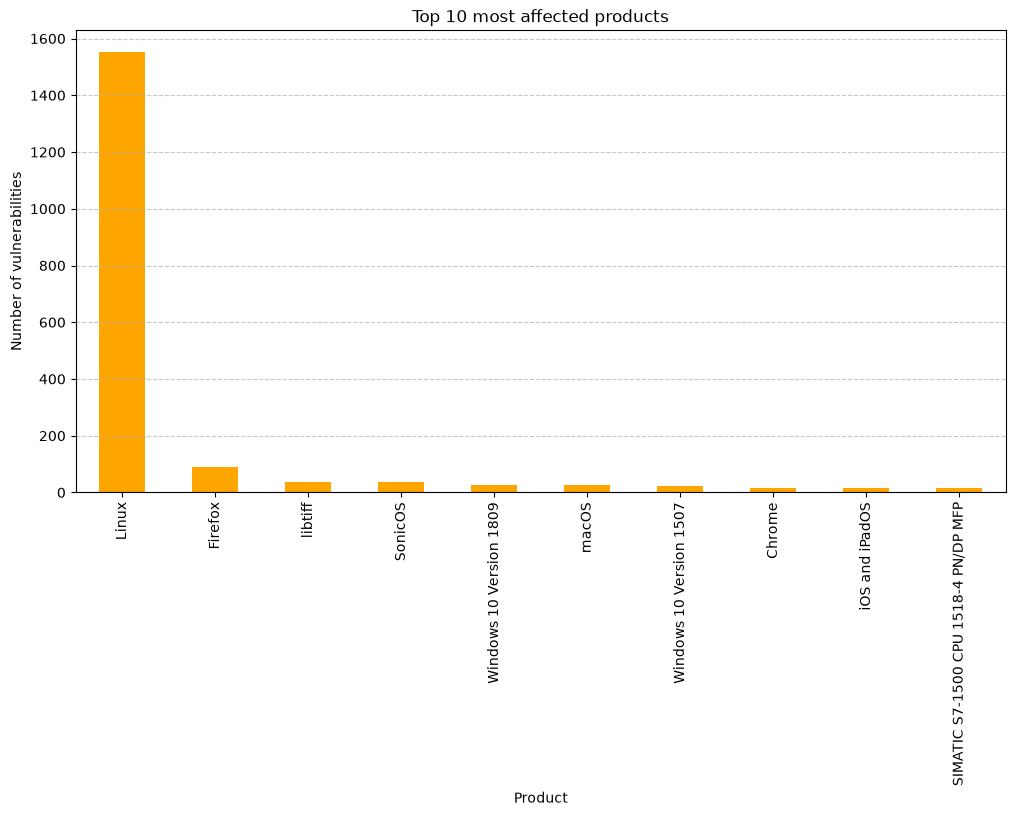

In [9]:
plt.figure(figsize=(12, 6))
df["Product"].value_counts().head(10).plot(kind="bar", color="orange")
plt.title("Top 10 most affected products")
plt.xlabel("Product")
plt.ylabel("Number of vulnerabilities")
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Vulnerabilities over time by CVSS range

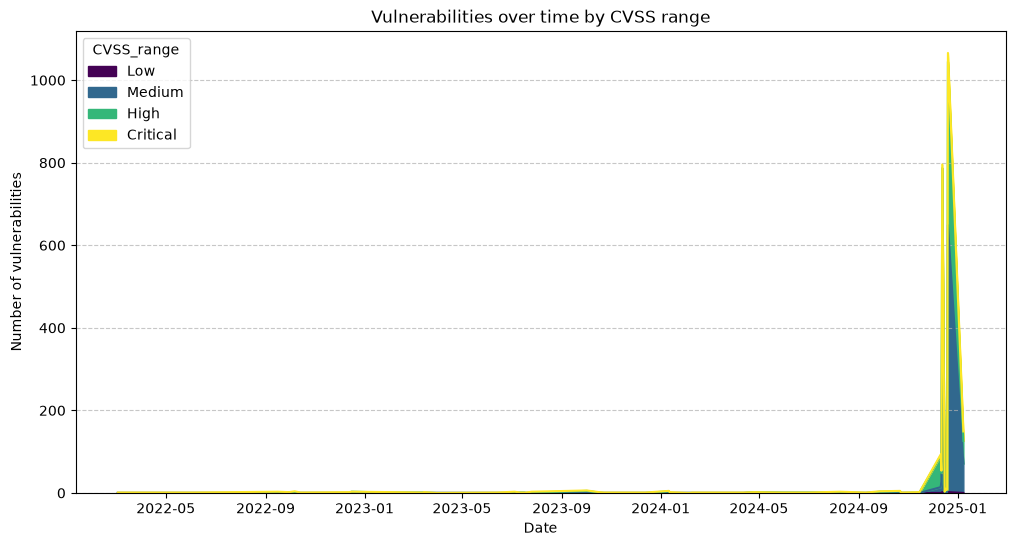

In [10]:
df["CVSS_range"] = pd.cut(df["CVSS"], bins=[0, 3, 6, 9, 10], labels=["Low", "Medium", "High", "Critical"])
vuln_per_date_cvss = df.groupby([df["Date"].dt.date, "CVSS_range"], observed=False).size().unstack().fillna(0)
vuln_per_date_cvss.plot.area(stacked=True, figsize=(12, 6), colormap="viridis")
plt.title("Vulnerabilities over time by CVSS range")
plt.xlabel("Date")
plt.ylabel("Number of vulnerabilities")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Weakness types (CWE), pie chart

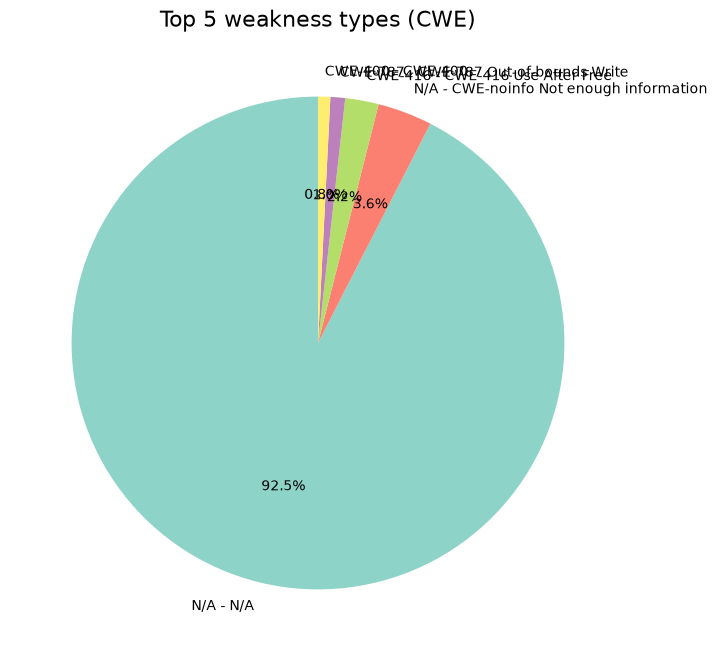

In [11]:
cwe_counts = df['CWE'].value_counts().head(5)
plt.figure(figsize=(8, 8))
cwe_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, cmap="Set3")
plt.title("Top 5 weakness types (CWE)", fontsize=16)
plt.ylabel("")
plt.show()